# Unstructured Text Analysis & Automated Triage with TF-IDF
**Course:** Data Science Tools & Techniques

Run top to bottom in Google Colab (**Runtime → Run all**). Dataset and NLTK data download automatically.
Plots are saved as `top_features.png`, `cluster_heatmap.png`, `spatial_mapping.png` (Files panel, left sidebar).

In [1]:
!pip install -q numpy pandas scikit-learn nltk matplotlib seaborn

# Unstructured Text Analysis & Automated Triage with TF-IDF
## Setup & Dataset Loading

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required NLTK resources quietly
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Load 4 real-world unstructured user discussion categories
CATEGORIES = [
    "sci.electronics",
    "rec.autos",
    "comp.sys.mac.hardware",
    "sci.med",
]

print("Loading dataset...")
raw_data = fetch_20newsgroups(
    subset="all",
    categories=CATEGORIES,
    remove=("headers", "footers", "quotes"),
)

df = pd.DataFrame(
    {
        "text": raw_data.data,
        "true_label": [raw_data.target_names[i] for i in raw_data.target],
    }
)

# Keep posts with meaningful length (> 50 characters)
df = df[df["text"].str.strip().str.len() > 50].reset_index(drop=True)
print(f"Loaded {len(df)} unstructured user posts.\n")

Loading dataset...
Loaded 3703 unstructured user posts.



## Step 1: Text Cleaning, Tokenization & Normalization

In [3]:
sample_post = df["text"].iloc[0][:400]
print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)

# TODO 1.1: tokenize, lowercase, keep alphabetic tokens only
tokens = [w.lower() for w in word_tokenize(sample_post) if w.isalpha()]

# TODO 1.2: remove standard English stopwords
stop_words = set(stopwords.words("english"))
filtered_tokens = [w for w in tokens if w not in stop_words]

# TODO 1.3: PorterStemmer vs WordNetLemmatizer (pos='v') on the same tokens
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]
lemmatized_tokens = [lemmatizer.lemmatize(w, pos="v") for w in filtered_tokens]

if filtered_tokens is not None:
    print("Filtered Tokens: ", filtered_tokens[:12])
    print("Stemmed Roots:   ", stemmed_tokens[:12])
    print("Lemmatized Words:", lemmatized_tokens[:12])

# Side-by-side comparison where the two methods disagree
cmp = pd.DataFrame(
    {"token": filtered_tokens, "porter_stem": stemmed_tokens, "lemma_verb": lemmatized_tokens}
)
print("\nTokens where Stemmer and Lemmatizer differ:")
print(cmp[cmp["porter_stem"] != cmp["lemma_verb"]].head(10).to_string(index=False))

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------
Filtered Tokens:  ['honda', 'cable', 'release', 'locked', 'ignition', 'key', 'valet', 'key', 'left', 'someone', 'unlock', 'trunk']
Stemmed Roots:    ['honda', 'cabl', 'releas', 'lock', 'ignit', 'key', 'valet', 'key', 'left', 'someon', 'unlock', 'trunk']
Lemmatized Words: ['honda', 'cable', 'release', 'lock', 'ignition', 'key', 'valet', 'key', 'leave', 'someone', 'unlock', 'trunk']

Tokens where Stemmer and Lemmatizer differ:
   token porter_stem lemma_verb
   cable        cabl      cable
 release      releas    release
ignition       ignit   ignition
    left        left      leave
 someone      someon    someone
  enable       enabl     enable
   cable        cabl      cable
 release      releas    release


## Step 2: Bag of Words vs. TF-IDF Feature Extraction


BoW   Matrix Shape: (3703, 4000)
TF-IDF Matrix Shape: (3703, 4000) | Sparsity: 99.04%


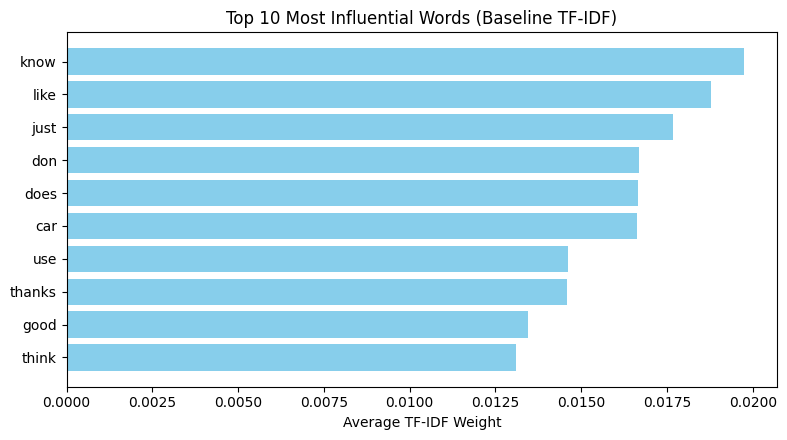

In [14]:
# TODO 2.1
bow_vec = CountVectorizer(stop_words="english", max_features=4000, min_df=5)
tfidf_vec = TfidfVectorizer(stop_words="english", max_features=4000, min_df=5)

# TODO 2.2
X_bow = bow_vec.fit_transform(df["text"])
X_tfidf = tfidf_vec.fit_transform(df["text"])

# TODO 2.3: sparsity
total_elements = X_tfidf.shape[0] * X_tfidf.shape[1]
sparsity = 100.0 * (1.0 - (X_tfidf.nnz / total_elements))
print(f"\nBoW   Matrix Shape: {X_bow.shape}")
print(f"TF-IDF Matrix Shape: {X_tfidf.shape} | Sparsity: {sparsity:.2f}%")

# TODO 2.4: Top 10 words by average TF-IDF
tfidf_means = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_idx = tfidf_means.argsort()[-10:]
top_words = tfidf_vec.get_feature_names_out()[top_idx]
top_scores = tfidf_means[top_idx]

plt.figure(figsize=(8, 4.5))
plt.barh(top_words, top_scores, color="skyblue")
plt.xlabel("Average TF-IDF Weight")
plt.title("Top 10 Most Influential Words (Baseline TF-IDF)")
plt.tight_layout()
plt.savefig("top_features.png", dpi=150)
plt.show()

## Step 3: Automated Topic Discovery & Spatial Mapping


=== Top 8 defining words per cluster (baseline) ===
Cluster 0 (n=2400): know, like, don, just, does, use, thanks, good
Cluster 1 (n=71): dsl, cadre, n3jxp, chastity, shameful, surrender, intellect, skepticism
Cluster 2 (n=529): car, cars, engine, new, just, ford, dealer, like
Cluster 3 (n=703): mac, apple, drive, monitor, card, thanks, does, know


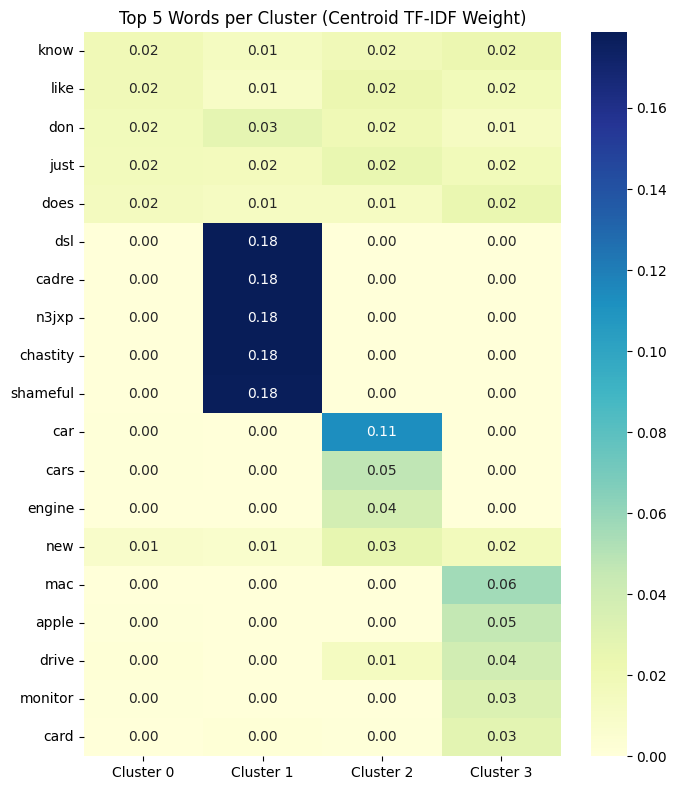

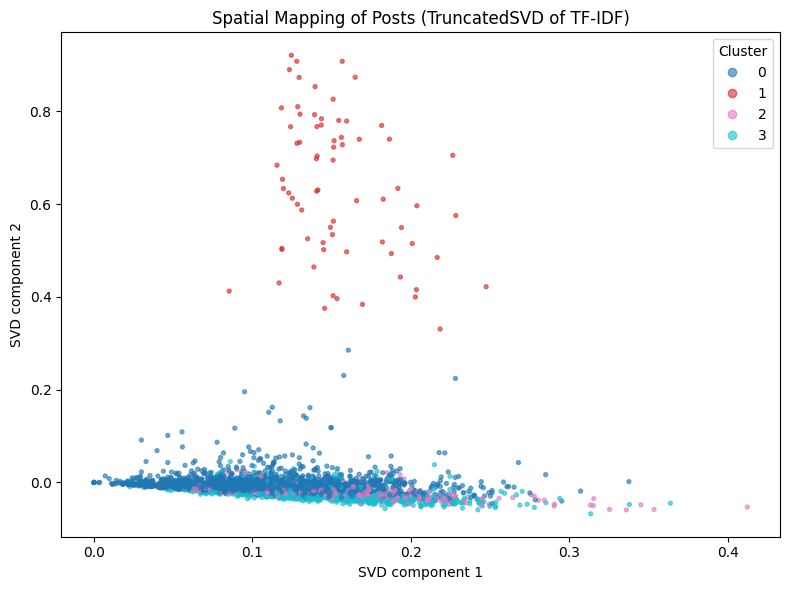

In [5]:
terms = tfidf_vec.get_feature_names_out()

# TODO 3.1
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_tfidf)


def top_cluster_words(model, feature_names, n):
    """Return {cluster_id: [top-n words by centroid weight]}."""
    order = model.cluster_centers_.argsort(axis=1)[:, ::-1]
    return {c: [feature_names[i] for i in order[c, :n]] for c in range(model.n_clusters)}


# TODO 3.2: top 8 words per centroid + heatmap of top 5 per cluster
print("\n=== Top 8 defining words per cluster (baseline) ===")
for c, words in top_cluster_words(kmeans, terms, 8).items():
    print(f"Cluster {c} (n={int((df['cluster'] == c).sum())}): {', '.join(words)}")


def plot_cluster_heatmap(model, feature_names, filename, title):
    top5 = top_cluster_words(model, feature_names, 5)
    union = []
    for c in range(model.n_clusters):
        for w in top5[c]:
            if w not in union:
                union.append(w)
    idx = [list(feature_names).index(w) for w in union]
    heat = pd.DataFrame(
        model.cluster_centers_[:, idx].T,
        index=union,
        columns=[f"Cluster {c}" for c in range(model.n_clusters)],
    )
    plt.figure(figsize=(7, 8))
    sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()


plot_cluster_heatmap(
    kmeans, terms, "cluster_heatmap.png", "Top 5 Words per Cluster (Centroid TF-IDF Weight)"
)

# TODO 3.3: 2D projection with TruncatedSVD
svd = TruncatedSVD(n_components=2, random_state=42)
coords = svd.fit_transform(X_tfidf)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="tab10", s=8, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("SVD component 1")
plt.ylabel("SVD component 2")
plt.title("Spatial Mapping of Posts (TruncatedSVD of TF-IDF)")
plt.tight_layout()
plt.savefig("spatial_mapping.png", dpi=150)
plt.show()

## Step 4: Problem-Solving Diagnostics

### Challenge 1: Conversational filler & numeric noise

   know: appears in  22.7% of posts | idf=2.48 | mean tfidf=0.0197
   like: appears in  23.4% of posts | idf=2.45 | mean tfidf=0.0188
  think: appears in  15.2% of posts | idf=2.88 | mean tfidf=0.0131
   just: appears in  21.2% of posts | idf=2.55 | mean tfidf=0.0177
   does: appears in  17.3% of posts | idf=2.75 | mean tfidf=0.0167
    use: appears in  17.1% of posts | idf=2.77 | mean tfidf=0.0146
 thanks: appears in  13.0% of posts | idf=3.04 | mean tfidf=0.0146

=== Top 8 words per cluster: CLEANED ===
Cluster 0: geb, pitt, dsl, cadre, chastity, surrender, shameful, intellect
Cluster 1: car, cars, engine, oil, dealer, miles, ford, speed
Cluster 2: mac, apple, drive, monitor, card, scsi, video, simms
Cluster 3: people, edu, information, help, work, problem, sure, right


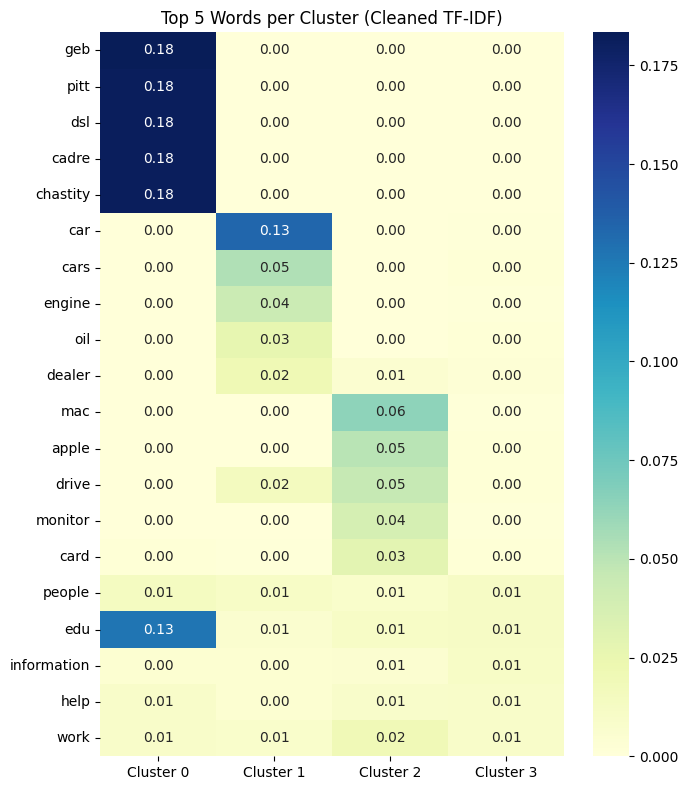

In [6]:
# How much weight does a filler word get in the baseline model?
N = X_tfidf.shape[0]
df_counts = np.asarray((X_tfidf > 0).sum(axis=0)).ravel()
for w in ["know", "like", "think", "just", "does", "use", "thanks"]:
    if w in terms:
        j = list(terms).index(w)
        print(
            f"{w:>7}: appears in {100 * df_counts[j] / N:5.1f}% of posts | "
            f"idf={tfidf_vec.idf_[j]:.2f} | mean tfidf={tfidf_means[j]:.4f}"
        )

# TODO 4.1: cleaner vectorizer
custom_stopwords = list(
    ENGLISH_STOP_WORDS.union(
        {"know", "like", "just", "think", "does", "use", "thanks", "don", "doesn",
         "didn", "ve", "ll", "im", "need", "want", "got", "good", "really", "way",
         "make", "going", "say", "thing", "things", "used", "using", "new", "time"}
    )
)
tfidf_clean_vec = TfidfVectorizer(
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    max_df=0.5,
    min_df=5,
    max_features=4000,
    stop_words=custom_stopwords,
)
X_clean = tfidf_clean_vec.fit_transform(df["text"])
kmeans_clean = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_clean"] = kmeans_clean.fit_predict(X_clean)

clean_terms = tfidf_clean_vec.get_feature_names_out()
print("\n=== Top 8 words per cluster: CLEANED ===")
for c, words in top_cluster_words(kmeans_clean, clean_terms, 8).items():
    print(f"Cluster {c}: {', '.join(words)}")

plot_cluster_heatmap(
    kmeans_clean, clean_terms, "cluster_heatmap_clean.png",
    "Top 5 Words per Cluster (Cleaned TF-IDF)",
)

### Challenge 2: Hardware vocabulary overlap

In [7]:
# TODO 4.2
print("\n=== Crosstab: true label vs baseline cluster ===")
ct = pd.crosstab(df["true_label"], df["cluster"])
print(ct)

print("\n=== Crosstab: true label vs cleaned cluster ===")
print(pd.crosstab(df["true_label"], df["cluster_clean"]))

# Which two categories overlap the most? Look at the cluster that mixes the most categories.
HW_A, HW_B = "sci.electronics", "comp.sys.mac.hardware"
ct_norm = ct.div(ct.sum(axis=1), axis=0).round(3)
print("\nRow-normalised crosstab (share of each category landing in each cluster):")
print(ct_norm)

# Shared technical vocabulary: words strongly weighted in BOTH hardware categories
mean_by_cat = {
    cat: np.asarray(X_tfidf[(df["true_label"] == cat).values].mean(axis=0)).ravel()
    for cat in [HW_A, HW_B]
}
top_n_each = 60
top_A = set(np.argsort(mean_by_cat[HW_A])[::-1][:top_n_each])
top_B = set(np.argsort(mean_by_cat[HW_B])[::-1][:top_n_each])
shared = sorted(top_A & top_B, key=lambda j: -(mean_by_cat[HW_A][j] + mean_by_cat[HW_B][j]))
print("\nTechnical words shared by electronics AND mac hardware posts:")
print([terms[j] for j in shared[:15]])

# Inspect a few misclustered posts (electronics posts living in the Mac-dominated cluster)
mac_cluster = ct.loc[HW_B].idxmax()
mis = df[(df["true_label"] == HW_A) & (df["cluster"] == mac_cluster)]
print(f"\n{len(mis)} electronics posts landed in the Mac cluster ({mac_cluster}). Examples:")
for t in mis["text"].head(3):
    print("  >", " ".join(t.split())[:220], "...")

# Bigrams: ngram_range=(1, 2)
tfidf_bi = TfidfVectorizer(
    stop_words=custom_stopwords, token_pattern=r"\b[a-zA-Z]{3,}\b",
    ngram_range=(1, 2), max_df=0.5, min_df=5, max_features=6000,
)
X_bi = tfidf_bi.fit_transform(df["text"])
kmeans_bi = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_bi"] = kmeans_bi.fit_predict(X_bi)

print("\n=== Crosstab: true label vs BIGRAM cluster ===")
print(pd.crosstab(df["true_label"], df["cluster_bi"]))
bi_terms = tfidf_bi.get_feature_names_out()
print("\nTop 8 terms per cluster with bigrams:")
for c, words in top_cluster_words(kmeans_bi, bi_terms, 8).items():
    print(f"Cluster {c}: {', '.join(words)}")

from sklearn.metrics import adjusted_rand_score
for name, col in [("baseline", "cluster"), ("cleaned", "cluster_clean"), ("bigram", "cluster_bi")]:
    print(f"Adjusted Rand Index ({name}): {adjusted_rand_score(df['true_label'], df[col]):.3f}")


=== Crosstab: true label vs baseline cluster ===
cluster                  0   1    2    3
true_label                              
comp.sys.mac.hardware  269   0    2  639
rec.autos              396   0  507    2
sci.electronics        860   0   20   60
sci.med                875  71    0    2

=== Crosstab: true label vs cleaned cluster ===
cluster_clean           0    1    2    3
true_label                              
comp.sys.mac.hardware   0    1  591  318
rec.autos               0  446    2  457
sci.electronics         0   18   45  877
sci.med                72    0    2  874

Row-normalised crosstab (share of each category landing in each cluster):
cluster                    0      1      2      3
true_label                                       
comp.sys.mac.hardware  0.296  0.000  0.002  0.702
rec.autos              0.438  0.000  0.560  0.002
sci.electronics        0.915  0.000  0.021  0.064
sci.med                0.923  0.075  0.000  0.002

Technical words shared by electro

### Challenge 3: Rant length bias

In [8]:
# TODO 4.3
lengths = df["text"].str.len()
longest_i, shortest_i = int(lengths.idxmax()), int(lengths.idxmin())

rows = []
for label, i in [("longest", longest_i), ("shortest", shortest_i)]:
    rows.append(
        {
            "post": label,
            "chars": int(lengths[i]),
            "L2 norm (BoW)": np.linalg.norm(X_bow[i].toarray()),
            "L2 norm (TF-IDF)": np.linalg.norm(X_tfidf[i].toarray()),
        }
    )
norm_table = pd.DataFrame(rows)
print("\n", norm_table.to_string(index=False))


     post  chars  L2 norm (BoW)  L2 norm (TF-IDF)
 longest  72161     276.240837               1.0
shortest     52       2.000000               1.0


### Challenge 4: Regulated compliance explainability

In [9]:
def explain_document(doc_id, matrix, vectorizer, top_n=5):
    """Return the top_n highest-weighted non-zero TF-IDF terms for one document
    as a list of (term, weight) tuples, sorted by weight (descending)."""
    row = matrix[doc_id]
    row = row.tocoo() if hasattr(row, "tocoo") else row
    feature_names = vectorizer.get_feature_names_out()
    pairs = sorted(zip(row.col, row.data), key=lambda p: -p[1])[:top_n]
    return [(feature_names[j], float(w)) for j, w in pairs]


# TODO 4.4: audit Document #412
doc_id = 412
print(f"\n=== Audit: why was Document #{doc_id} routed where it was? ===")
print(f"True label : {df.loc[doc_id, 'true_label']}")
print(f"Cluster    : {df.loc[doc_id, 'cluster']}")
for term, weight in explain_document(doc_id, X_tfidf, tfidf_vec, top_n=5):
    print(f"  {term:<15} {weight:.4f}")
print("\nPost preview:", " ".join(df.loc[doc_id, "text"].split())[:300], "...")


=== Audit: why was Document #412 routed where it was? ===
True label : rec.autos
Cluster    : 0
  discussion      0.4524
  feel            0.3989
  days            0.3855
  need            0.2885
  meant           0.2667

Post preview: Could we plase cease this discussion. I fail to see why people feel the need to expound upon this issue for days and days on end. These areas are not meant for this type of discussion. If you feel the need to do such things, please take your thought elsewhere. Thanks. ...
